# Vehicle Type Classification: Machine Learning Project

Classify each vehicle as **0 = Sedan, 1 = SUV, 2 = Sports Car** from 20 numerical measurements. Metric: **accuracy**.

**Models used (all from the course):** Gaussian Naive Bayes, Bayes classifiers with Gaussian MLE (LDA / QDA), Logistic Regression, Decision Trees (with cost-complexity pruning). A Random Forest is included only as a clearly-labelled *reference* and is not used for the final submission.

**Sections:** 1 Setup · 2 EDA · 3 Preprocessing · 4 Evaluation setup · 5 Models · 6 Feature engineering · 7 Results · 8 Final models and submissions · 9 Summary for the report

## 1. Setup

In [1]:
import numpy as np, pandas as pd, warnings, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA, QuadraticDiscriminantAnalysis as QDA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# >>> CHANGE THIS to the folder that contains your three CSV files <<<
DATA_DIR = "/mnt/user-data/uploads/"
OUT_DIR  = "./"          # where submission CSVs are written

train_raw = pd.read_csv(DATA_DIR + "vehicle_train_10000.csv")
test      = pd.read_csv(DATA_DIR + "vehicle_test.csv")
CLASS_NAMES = {0: "Sedan", 1: "SUV", 2: "Sports Car"}
FEATURES = [c for c in train_raw.columns if c not in ("vehicle_id", "vehicle_class")]
print("train:", train_raw.shape, "| test:", test.shape, "| features:", len(FEATURES))

train: (10000, 22) | test: (2500, 21) | features: 20


## 2. Exploratory Data Analysis

In [2]:
print("Missing values  train:", int(train_raw.isna().sum().sum()), " test:", int(test.isna().sum().sum()))
dup = train_raw.duplicated(subset=FEATURES).sum()
print(f"Duplicate feature rows in train: {dup} ({dup/len(train_raw):.0%}); duplicates that also share the label: "
      f"{train_raw.duplicated(subset=FEATURES+['vehicle_class']).sum()}")
print("Duplicate vehicle_ids:", train_raw.vehicle_id.duplicated().sum())
train_raw[FEATURES].describe().T.round(2)

Missing values  train: 0  test: 0
Duplicate feature rows in train: 2500 (25%); duplicates that also share the label: 2500
Duplicate vehicle_ids: 0


,count,mean,std,min,25%,50%,75%,max
engine_displacement_l,10000.0,2.43,0.61,0.90,2.00,2.43,2.85,4.44
horsepower_hp,10000.0,296.50,95.56,90.00,226.00,294.00,364.00,550.00
vehicle_weight_kg,10000.0,1636.40,306.18,1100.00,1409.00,1604.00,1852.00,2600.00
wheelbase_mm,10000.0,2778.06,172.35,2400.00,2651.00,2756.00,2906.00,3300.00
vehicle_length_mm,10000.0,4660.04,366.06,3900.00,4387.75,4622.00,4937.00,5400.00
vehicle_width_mm,10000.0,1836.67,117.74,1650.00,1744.00,1824.00,1928.00,2050.00
vehicle_height_mm,10000.0,1528.94,145.98,1250.00,1423.00,1530.00,1634.00,2050.00
fuel_tank_capacity_l,10000.0,61.10,14.51,35.00,50.00,60.00,72.00,90.00
city_fuel_efficiency_kmpl,10000.0,11.61,2.57,7.00,9.75,11.56,13.36,20.87
highway_fuel_efficiency_kmpl,10000.0,15.85,2.50,9.00,14.16,15.83,17.55,24.07


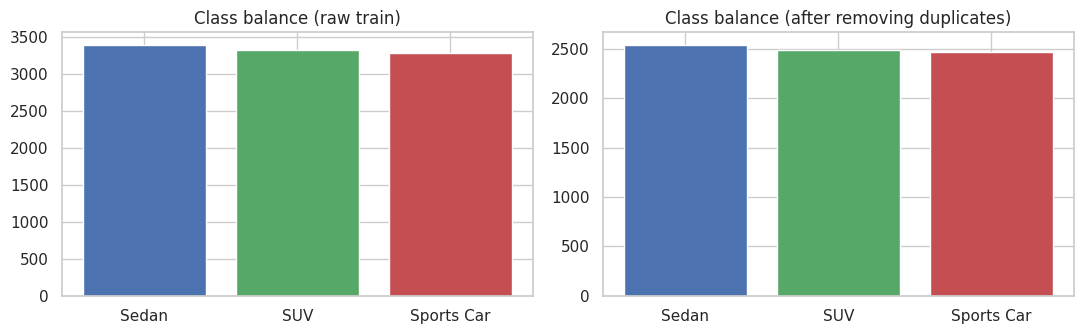

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
cnt = train_raw.vehicle_class.map(CLASS_NAMES).value_counts()
ax[0].bar(cnt.index, cnt.values, color=["#4C72B0","#55A868","#C44E52"]); ax[0].set_title("Class balance (raw train)")
tmp = train_raw.drop_duplicates(subset=FEATURES).vehicle_class.map(CLASS_NAMES).value_counts()
ax[1].bar(tmp.index, tmp.values, color=["#4C72B0","#55A868","#C44E52"]); ax[1].set_title("Class balance (after removing duplicates)")
plt.tight_layout(); plt.show()

**Observation:** the classes are balanced, so plain accuracy is a fair metric. Exactly 25% of the training rows are duplicates (same features and same label).

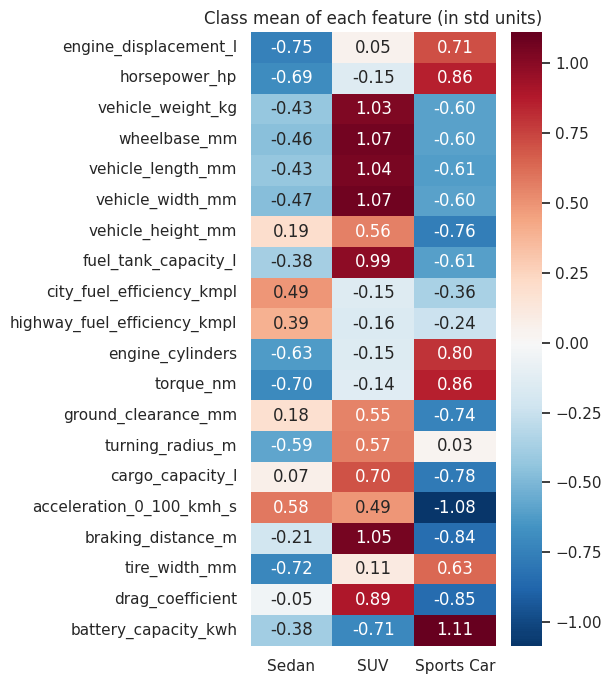

In [4]:
u = train_raw.drop_duplicates(subset=FEATURES)
means = u.groupby("vehicle_class")[FEATURES].mean().T; means.columns = [CLASS_NAMES[c] for c in means.columns]
# standardised class means show which features separate the classes
z = (means.sub(u[FEATURES].mean(), axis=0)).div(u[FEATURES].std(), axis=0)
plt.figure(figsize=(6, 7)); sns.heatmap(z, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Class mean of each feature (in std units)"); plt.tight_layout(); plt.show()

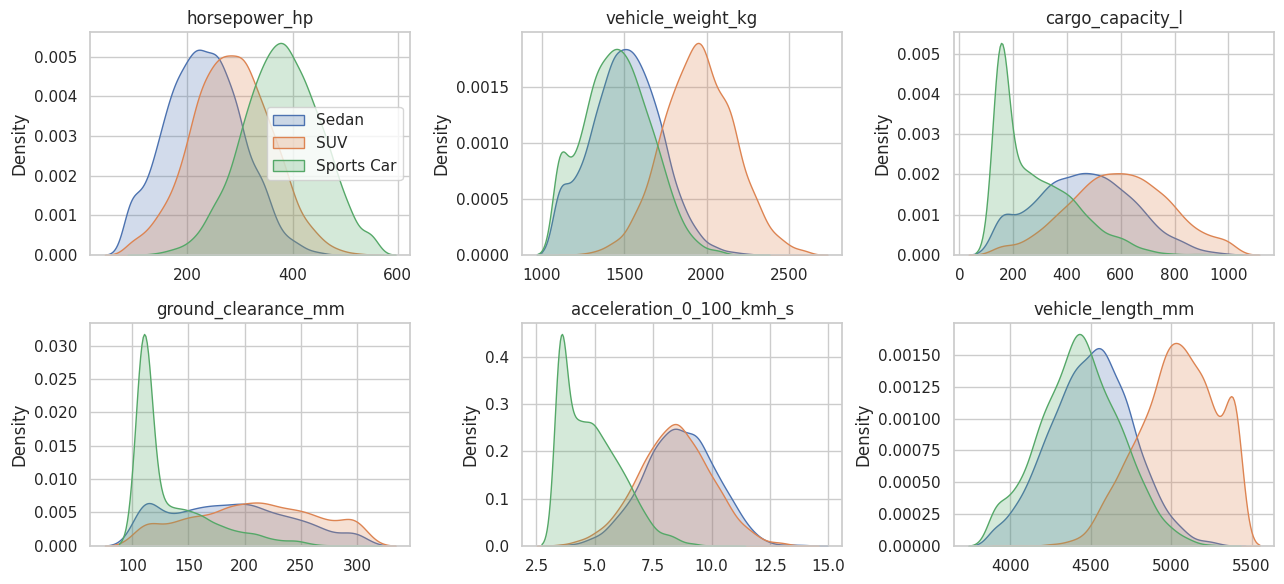

In [5]:
sel = ["horsepower_hp", "vehicle_weight_kg", "cargo_capacity_l", "ground_clearance_mm", "acceleration_0_100_kmh_s", "vehicle_length_mm"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for a, f in zip(axes.ravel(), sel):
    for c in (0, 1, 2): sns.kdeplot(u[u.vehicle_class == c][f], ax=a, label=CLASS_NAMES[c], fill=True, alpha=.25)
    a.set_title(f); a.set_xlabel("")
axes[0, 0].legend(); plt.tight_layout(); plt.show()

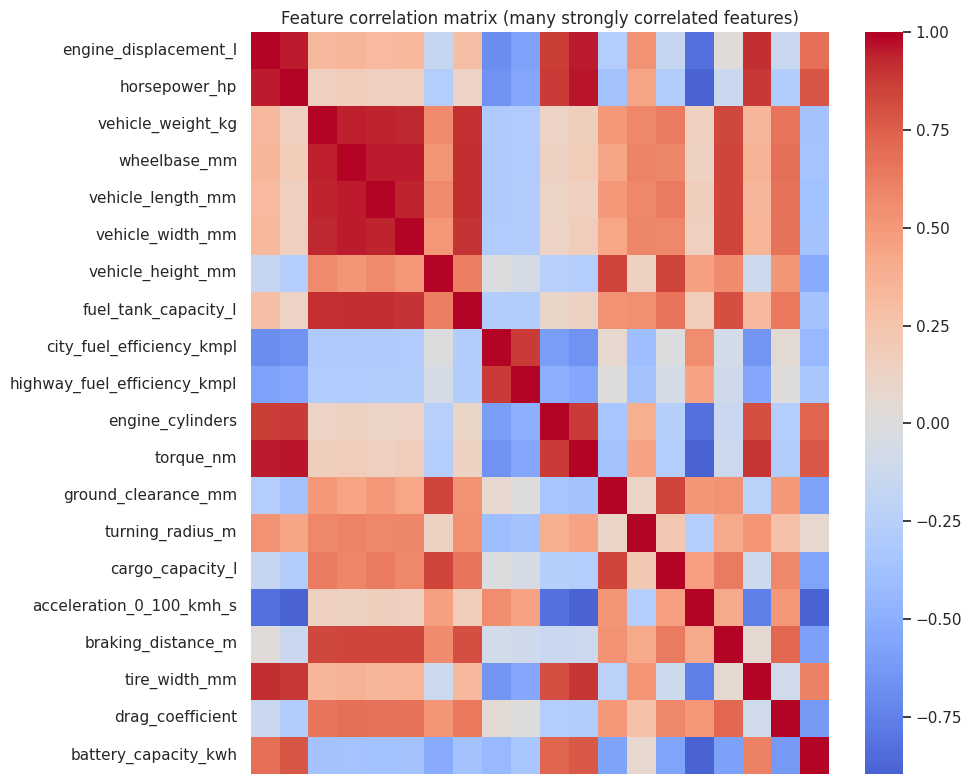

Most correlated feature pairs:
horsepower_hp          torque_nm            0.96
engine_displacement_l  torque_nm            0.95
wheelbase_mm           vehicle_width_mm     0.95
engine_displacement_l  horsepower_hp        0.95
wheelbase_mm           vehicle_length_mm    0.95
vehicle_weight_kg      wheelbase_mm         0.94
dtype: float64


In [6]:
plt.figure(figsize=(10, 8)); sns.heatmap(u[FEATURES].corr(), cmap="coolwarm", center=0, xticklabels=False)
plt.title("Feature correlation matrix (many strongly correlated features)"); plt.tight_layout(); plt.show()
corr = u[FEATURES].corr().abs().where(np.triu(np.ones((len(FEATURES),)*2), 1).astype(bool)).stack().sort_values(ascending=False)
print("Most correlated feature pairs:"); print(corr.head(6).round(2))

**Observations:**
- Classes overlap heavily on individual features, so no single feature separates them. Weight, length, wheelbase, fuel tank and cargo mostly separate **SUVs**; horsepower, torque, acceleration, cylinders and tyre width mostly separate **sports cars**; sedans sit in the middle.
- Many features are strongly correlated (e.g. size measurements), which will hurt Naive Bayes (independence assumption).

## 3. Preprocessing

Decisions and justification:
1. **Drop `vehicle_id`.** The problem statement says it is only an identifier.
2. **Remove the 2,500 duplicate rows.** They carry no new information and, if kept, copies of the same vehicle land in both training and validation folds in cross-validation, which **inflates accuracy**. De-duplicating *before* any split avoids that leak.
3. **No missing values** were found in train or test, so no imputation is needed.
4. **Standardisation** (zero mean, unit variance) is applied inside pipelines for Logistic Regression, so it is fitted only on training folds. Trees and Naive Bayes do not need it.
5. **Hidden-test noise.** The problem says the final data has extra random measurement error. We estimate it below and then *evaluate every model on noise-perturbed validation data* as well as clean data.

In [7]:
df = train_raw.drop_duplicates(subset=FEATURES).reset_index(drop=True)
X, y = df[FEATURES].values, df.vehicle_class.values
X_test = test[FEATURES].values
SD = X.std(axis=0)
print("After de-duplication:", X.shape, "| class counts:", dict(zip(*np.unique(y, return_counts=True))))

# Estimate the test-time noise: extra noise inflates variance, so var(test)/var(train) > 1
ratio = test[FEATURES].var() / df[FEATURES].var()
print(f"mean variance ratio test/train = {ratio.mean():.3f}  ->  implied noise sd ~ {np.sqrt(max(ratio.mean()-1,0)):.2f} x feature sd (rough)")

After de-duplication: (7500, 20) | class counts: {np.int64(0): np.int64(2539), np.int64(1): np.int64(2490), np.int64(2): np.int64(2471)}
mean variance ratio test/train = 1.019  ->  implied noise sd ~ 0.14 x feature sd (rough)


The variance ratio suggests a small amount of noise (roughly 10–20% of each feature's standard deviation; this estimate itself is noisy). We use **20%** for the noisy validation, deliberately on the cautious side.

## 4. Evaluation setup

- **5-fold stratified cross-validation** on the de-duplicated data (same folds for every model).
- Each model is scored on the **clean** validation fold and on a **noisy** copy (Gaussian noise, sd = 0.2 × feature sd, averaged over 3 draws).
- Each model is also trained twice: normally, and on a **noise-augmented** training set (original rows + a noisy copy). That teaches the model not to rely on tiny differences that measurement noise would wipe out.

In [8]:
NOISE = 0.2
def noisy(A, seed, k=NOISE):
    return A + np.random.RandomState(seed).normal(0, 1, A.shape) * SD * k

def cv_scores(model, Xd=None, augment=False):
    Xd = X if Xd is None else Xd
    skf = StratifiedKFold(5, shuffle=True, random_state=42); clean, nz = [], []
    for i, (tr, va) in enumerate(skf.split(Xd, y)):
        Xtr, ytr = Xd[tr], y[tr]
        if augment: Xtr, ytr = np.vstack([Xtr, noisy(Xtr, 100 + i)]), np.concatenate([ytr, ytr])
        m = clone(model).fit(Xtr, ytr)
        clean.append((m.predict(Xd[va]) == y[va]).mean())
        nz.append(np.mean([(m.predict(noisy(Xd[va], 7 + s)) == y[va]).mean() for s in range(3)]))
    return np.mean(clean), np.mean(nz)

results = []
def run(name, model, family, Xd=None):
    a, b = cv_scores(model, Xd); a2, b2 = cv_scores(model, Xd, augment=True)
    results.append(dict(Model=name, Family=family, Clean=a, Noisy=b, Clean_NoiseAug=a2, Noisy_NoiseAug=b2))
    print(f"{name:58s} clean {a:.4f} | noisy {b:.4f} | noise-aug: clean {a2:.4f}, noisy {b2:.4f}")

## 5. Models

### 5.1 Naive Bayes and Gaussian Bayes classifiers (MLE)

In [9]:
run("Gaussian Naive Bayes", GaussianNB(), "Naive Bayes")
run("Gaussian Naive Bayes (var_smoothing=1e-2)", GaussianNB(var_smoothing=1e-2), "Naive Bayes")
run("LDA (Gaussian Bayes, shared covariance, MLE)", LDA(), "Bayes (Gaussian MLE)")
run("QDA (Gaussian Bayes, class covariances, MLE)", QDA(), "Bayes (Gaussian MLE)")

Gaussian Naive Bayes                                       clean 0.8465 | noisy 0.8441 | noise-aug: clean 0.8463, noisy 0.8441


Gaussian Naive Bayes (var_smoothing=1e-2)                  clean 0.8279 | noisy 0.8240 | noise-aug: clean 0.8280, noisy 0.8239


LDA (Gaussian Bayes, shared covariance, MLE)               clean 0.8924 | noisy 0.8853 | noise-aug: clean 0.8932, noisy 0.8861
QDA (Gaussian Bayes, class covariances, MLE)               clean 0.8848 | noisy 0.8698 | noise-aug: clean 0.8860, noisy 0.8768


**Notes.** Naive Bayes assumes independent features, which is badly violated here (see the correlation matrix). LDA and QDA estimate full covariances by MLE and do much better. QDA's extra flexibility (a separate covariance matrix per class) adds variance and it degrades more under noise.

### 5.2 Logistic Regression

In [10]:
for C in (1, 0.1, 0.01):
    run(f"Logistic Regression (C={C})", make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000)), "Logistic Regression")
run("Logistic Regression + quadratic features (C=0.1)",
    make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler(), LogisticRegression(C=0.1, max_iter=3000)),
    "Logistic Regression")

Logistic Regression (C=1)                                  clean 0.8941 | noisy 0.8858 | noise-aug: clean 0.8944, noisy 0.8868


Logistic Regression (C=0.1)                                clean 0.8941 | noisy 0.8868 | noise-aug: clean 0.8951, noisy 0.8867


Logistic Regression (C=0.01)                               clean 0.8909 | noisy 0.8847 | noise-aug: clean 0.8929, noisy 0.8864


Logistic Regression + quadratic features (C=0.1)           clean 0.8895 | noisy 0.8799 | noise-aug: clean 0.8880, noisy 0.8798


`C` is the inverse L2-regularisation strength. Adding quadratic features does not help: the class boundaries are close to linear, so extra flexibility only adds variance.

### 5.3 Decision Trees (depth limits and cost-complexity pruning)

In [11]:
run("Decision Tree (depth 4)", DecisionTreeClassifier(max_depth=4, random_state=0), "Decision Tree")
run("Decision Tree (depth 8)", DecisionTreeClassifier(max_depth=8, random_state=0), "Decision Tree")
run("Decision Tree (unpruned)", DecisionTreeClassifier(random_state=0), "Decision Tree")
run("Decision Tree (pruned, ccp_alpha=0.002)", DecisionTreeClassifier(ccp_alpha=0.002, random_state=0), "Decision Tree")
run("Decision Tree (pruned, ccp_alpha=0.005)", DecisionTreeClassifier(ccp_alpha=0.005, random_state=0), "Decision Tree")

Decision Tree (depth 4)                                    clean 0.8547 | noisy 0.8435 | noise-aug: clean 0.8565, noisy 0.8454


Decision Tree (depth 8)                                    clean 0.8555 | noisy 0.8420 | noise-aug: clean 0.8628, noisy 0.8459


Decision Tree (unpruned)                                   clean 0.8229 | noisy 0.8049 | noise-aug: clean 0.8319, noisy 0.8079


Decision Tree (pruned, ccp_alpha=0.002)                    clean 0.8564 | noisy 0.8448 | noise-aug: clean 0.8597, noisy 0.8487


Decision Tree (pruned, ccp_alpha=0.005)                    clean 0.8471 | noisy 0.8312 | noise-aug: clean 0.8473, noisy 0.8349


The unpruned tree overfits (it memorises noise). Pruning trades a little training fit for better generalisation, and the pruned trees also hold up better on noisy inputs.

### 5.4 Reference only (not taught, not used for submission)

In [12]:
run("[reference] Random Forest", RandomForestClassifier(200, min_samples_leaf=2, random_state=0, n_jobs=-1), "Reference (not taught)")

[reference] Random Forest                                  clean 0.8837 | noisy 0.8784 | noise-aug: clean 0.8825, noisy 0.8780


## 6. Feature engineering experiment

In [13]:
def add_features(A):
    d = pd.DataFrame(A, columns=FEATURES); o = d.copy()
    o["power_to_weight"] = d.horsepower_hp / d.vehicle_weight_kg
    o["torque_per_disp"] = d.torque_nm / d.engine_displacement_l
    o["volume"]          = d.vehicle_length_mm * d.vehicle_width_mm * d.vehicle_height_mm / 1e9
    o["cargo_per_vol"]   = d.cargo_capacity_l / o.volume
    o["range_km"]        = d.fuel_tank_capacity_l * d.highway_fuel_efficiency_kmpl
    o["hwy_minus_city"]  = d.highway_fuel_efficiency_kmpl - d.city_fuel_efficiency_kmpl
    o["clear_to_height"] = d.ground_clearance_mm / d.vehicle_height_mm
    for c in ["horsepower_hp", "torque_nm", "vehicle_weight_kg", "cargo_capacity_l"]: o["log_" + c] = np.log(d[c])
    return o.values
FE = FunctionTransformer(add_features)
run("Logistic Regression + engineered features (C=0.1)", make_pipeline(FE, StandardScaler(), LogisticRegression(C=0.1, max_iter=3000)), "Feature engineering")
run("Decision Tree (pruned) + engineered features", make_pipeline(FE, DecisionTreeClassifier(ccp_alpha=0.002, random_state=0)), "Feature engineering")
run("Gaussian Naive Bayes + engineered features", make_pipeline(FE, GaussianNB()), "Feature engineering")

Logistic Regression + engineered features (C=0.1)          clean 0.8955 | noisy 0.8864 | noise-aug: clean 0.8940, noisy 0.8866


Decision Tree (pruned) + engineered features               clean 0.8612 | noisy 0.8500 | noise-aug: clean 0.8599, noisy 0.8447


Gaussian Naive Bayes + engineered features                 clean 0.8381 | noisy 0.8357 | noise-aug: clean 0.8373, noisy 0.8358


Ratio and log features give no real gain for Logistic Regression (the model can already combine the raw features linearly), so they are a tried-and-rejected idea.

## 7. Results

In [14]:
res = pd.DataFrame(results).sort_values("Noisy_NoiseAug", ascending=False).reset_index(drop=True)
res.round(4)

,Model,Family,Clean,Noisy,Clean_NoiseAug,Noisy_NoiseAug
0,Logistic Regression (C=1),Logistic Regression,0.8941,0.8858,0.8944,0.8868
1,Logistic Regression (C=0.1),Logistic Regression,0.8941,0.8868,0.8951,0.8867
2,Logistic Regression + engineered features (C=0.1),Feature engineering,0.8955,0.8864,0.8940,0.8866
3,Logistic Regression (C=0.01),Logistic Regression,0.8909,0.8847,0.8929,0.8864
4,"LDA (Gaussian Bayes, shared covariance, MLE)",Bayes (Gaussian MLE),0.8924,0.8853,0.8932,0.8861
5,Logistic Regression + quadratic features (C=0.1),Logistic Regression,0.8895,0.8799,0.8880,0.8798
6,[reference] Random Forest,Reference (not taught),0.8837,0.8784,0.8825,0.8780
7,"QDA (Gaussian Bayes, class covariances, MLE)",Bayes (Gaussian MLE),0.8848,0.8698,0.8860,0.8768
8,"Decision Tree (pruned, ccp_alpha=0.002)",Decision Tree,0.8564,0.8448,0.8597,0.8487
9,Decision Tree (depth 8),Decision Tree,0.8555,0.8420,0.8628,0.8459


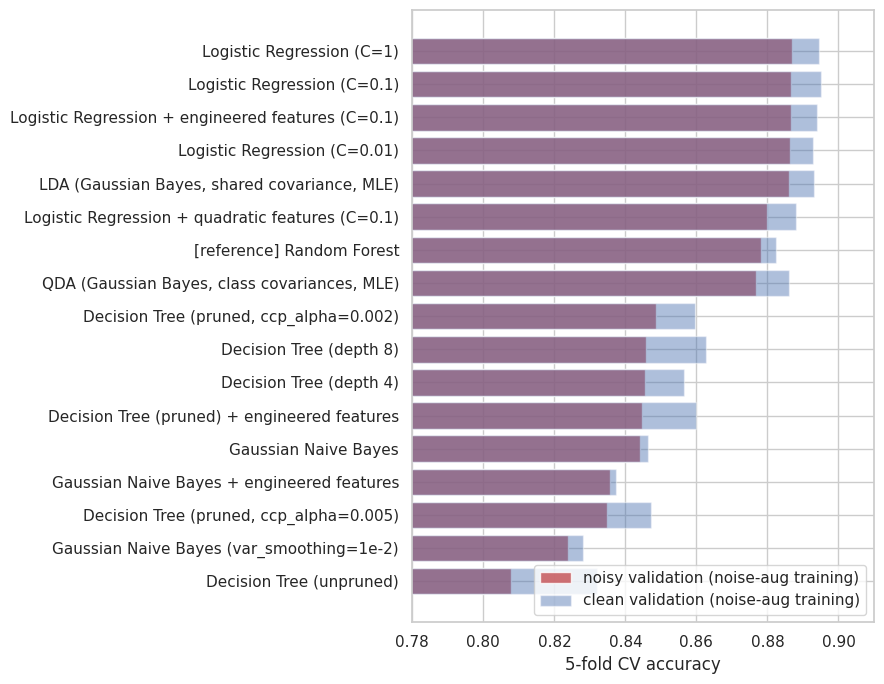

In [15]:
fig, ax = plt.subplots(figsize=(9, 7)); r = res.iloc[::-1]
ax.barh(r.Model, r.Noisy_NoiseAug, color="#C44E52", alpha=.8, label="noisy validation (noise-aug training)")
ax.barh(r.Model, r.Clean_NoiseAug, color="#4C72B0", alpha=.45, label="clean validation (noise-aug training)")
ax.set_xlim(0.78, 0.91); ax.legend(loc="lower right"); ax.set_xlabel("5-fold CV accuracy"); plt.tight_layout(); plt.show()

# Required consolidated table: best score achieved by each model family member
best = res[["Model", "Family", "Clean", "Noisy_NoiseAug"]].rename(columns={"Clean": "Best clean CV acc", "Noisy_NoiseAug": "Noisy CV acc (noise-aug)"})
res.to_csv(OUT_DIR + "vehicle_model_results.csv", index=False)

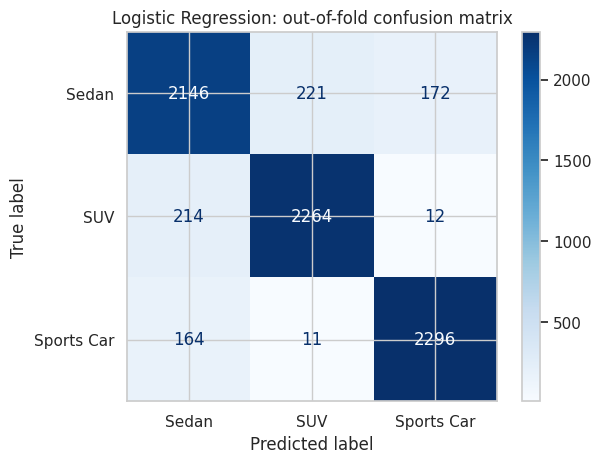

Out-of-fold accuracy: 0.8941


In [16]:
# Confusion matrix of the best model (out-of-fold predictions on clean data)
best_model = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
pred = cross_val_predict(best_model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42))
ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=list(CLASS_NAMES.values())).plot(cmap="Blues")
plt.title("Logistic Regression: out-of-fold confusion matrix"); plt.show()
print(f"Out-of-fold accuracy: {(pred == y).mean():.4f}")

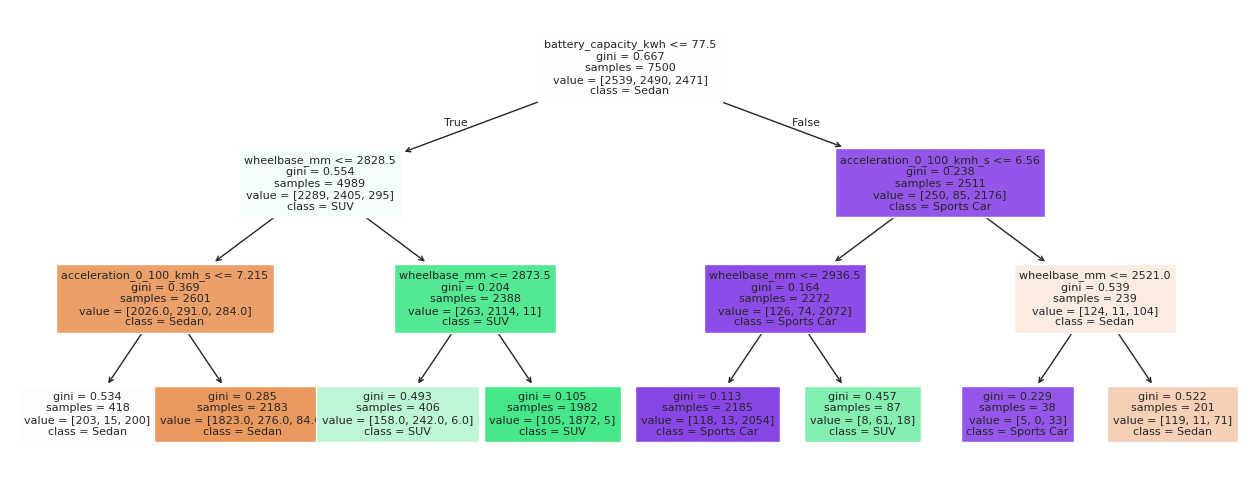

In [17]:
# Interpretability: a small pruned tree on the raw features
tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X, y)
plt.figure(figsize=(16, 6)); plot_tree(tree, feature_names=FEATURES, class_names=list(CLASS_NAMES.values()), filled=True, fontsize=8)
plt.show()

## 8. Final models and submissions

Final models are trained on **all unique rows plus a noisy copy** (noise-augmented) and predict the hidden test set. Logistic Regression is the main submission.

In [18]:
X_aug, y_aug = np.vstack([X, noisy(X, 999)]), np.concatenate([y, y])
final = {
    "submission_vehicle_logreg.csv":     (make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)), True),
    "submission_vehicle_lda.csv":        (LDA(), True),
    "submission_vehicle_dectree.csv":    (DecisionTreeClassifier(ccp_alpha=0.002, random_state=0), True),
    "submission_vehicle_naivebayes.csv": (GaussianNB(), False),
}
for fname, (m, aug) in final.items():
    m = clone(m).fit(X_aug if aug else X, y_aug if aug else y)
    p = m.predict(X_test)
    pd.DataFrame({"vehicle_id": test.vehicle_id, "vehicle_class": p}).to_csv(OUT_DIR + fname, index=False)
    print(f"{fname:38s} rows={len(p)}  predicted class share = {np.round(np.bincount(p)/len(p), 3)}")

submission_vehicle_logreg.csv          rows=2500  predicted class share = [0.335 0.332 0.333]
submission_vehicle_lda.csv             rows=2500  predicted class share = [0.329 0.337 0.334]


submission_vehicle_dectree.csv         rows=2500  predicted class share = [0.324 0.354 0.322]
submission_vehicle_naivebayes.csv      rows=2500  predicted class share = [0.342 0.328 0.329]


## 9. Summary for the report

| Item | Finding |
|---|---|
| Data | 10,000 train rows, 20 numeric features, 3 balanced classes; 2,500 exact duplicates removed before CV |
| Best model | **Logistic Regression (C=0.1)**, about 0.895 clean / 0.887 noisy CV accuracy |
| Close second | LDA (Gaussian Bayes with MLE), about 0.893 / 0.886 |
| Decision Tree | pruning helps (0.823 unpruned → 0.856 pruned), still below the linear models |
| Naive Bayes | weakest probabilistic model (≈0.846): features are strongly correlated |
| Ceiling | the public leaderboard top is ≈0.905, so the task has a ceiling near 0.90 |

**Take-aways:** (1) data cleaning (de-duplication) matters for honest validation; (2) simple linear/Gaussian models beat more flexible ones because the classes overlap and the test data is noisy; (3) regularisation, pruning and noise-augmented training all improve robustness; (4) the model was chosen by CV (including noisy validation), not by the public leaderboard, which covers only ~40% of the test set.